<a href="https://colab.research.google.com/github/samarae2508-design/week4_communityproject/blob/main/week2_community_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import joblib

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Libraries imported successfully.")

OpenCV: 5.0.0
NumPy: 2.4.6
Scikit-learn: 1.6.1
Libraries imported successfully.


In [ ]:
import numpy as np, tensorflow as tf
train = tf.keras.utils.image_dataset_from_directory(
    "/content/emotion_dataset/train", image_size=(48, 48), color_mode="grayscale")
val = tf.keras.utils.image_dataset_from_directory(
    "/content/emotion_dataset/val", image_size=(48, 48), color_mode="grayscale")
class_names = train.class_names          # use this, don't type it manually
print(class_names)

# put tf.keras.layers.Rescaling(1./255) as the FIRST layer of your model,
# then the same preprocessing applies automatically at prediction time
def predict(path):
    img = tf.keras.utils.load_img(path, color_mode="grayscale", target_size=(48, 48))
    x = np.expand_dims(tf.keras.utils.img_to_array(img), 0)
    p = model.predict(x)[0]
    print(dict(zip(class_names, p.round(3))))
    return class_names[np.argmax(p)]

FileNotFoundError: [Errno 2] No such file or directory: '/content/emotion_dataset/train'

In [ ]:
"""
Export a few held-out test images from the real-face dataset (emotion_dataset/val).
Run AFTER real_face_dataset_colab.py, in the same Colab session.

Creates test_samples/ with files named like test_anger_1.jpg (true label in the
name), shows them in a grid, and zips them so you can download them.
"""
import os
import random
import shutil
import matplotlib.pyplot as plt
from PIL import Image

SRC = "/content/emotion_dataset/val"      # corrected dataset path
DST = "test_samples"
PER_CLASS = 3                 # 3 x 3 classes = 9 images (use 2-3)
random.seed(7)

if os.path.exists(DST):
    shutil.rmtree(DST)
os.makedirs(DST)

paths = []
for label in sorted(os.listdir(SRC)):
    files = sorted(os.listdir(os.path.join(SRC, label)))
    for i, f in enumerate(random.sample(files, PER_CLASS), start=1):
        ext = os.path.splitext(f)[1]
        out = os.path.join(DST, f"test_{label}_{i}{ext}")
        shutil.copy(os.path.join(SRC, label, f), out)
        paths.append(out)

# preview with true labels
fig, axes = plt.subplots(len(paths) // PER_CLASS, PER_CLASS, figsize=(PER_CLASS * 2, len(paths) // PER_CLASS * 2))
for ax, p in zip(axes.flat, paths):
    ax.imshow(Image.open(p), cmap="gray")
    ax.set_title(os.path.basename(p).split("_")[1], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

# zip + download (optional)
shutil.make_archive("test_samples", "zip", DST)
try:
    from google.colab import files
    files.download("test_samples.zip")
except ImportError:
    pass

print("Test images saved in:", DST)
for p in paths:
    print(" ", p)

FileNotFoundError: [Errno 2] No such file or directory: '/content/emotion_dataset/val'

In [ ]:
import os

# Using the generated synthetic dataset
root = "emotion_dataset/train"

classes = sorted(os.listdir(root))
print("Using folder:", root)
print("Classes found:", classes)  # should print ['anger', 'neutral', 'smile']

Using folder: emotion_dataset/train
Classes found: ['anger', 'neutral', 'smile']


In [ ]:
DATASET_DIR = "/content/emotion_dataset"

import os

print(os.listdir(DATASET_DIR))

['val', 'train']


In [ ]:
import os

# Define the dataset directory using the 'root' variable from the previous cell
DATASET_DIR = root if 'root' in globals() else "dataset/fingers_final"

CLASSES = ["0", "1", "2", "3", "4", "5"]

for class_name in CLASSES:
    folder = os.path.join(DATASET_DIR, class_name)

    if not os.path.isdir(folder):
        print(f"Missing folder: {folder}")
        continue

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    print(f"Class {class_name}: {len(images)} images")

Missing folder: emotion_dataset/train/0
Missing folder: emotion_dataset/train/1
Missing folder: emotion_dataset/train/2
Missing folder: emotion_dataset/train/3
Missing folder: emotion_dataset/train/4
Missing folder: emotion_dataset/train/5


In [ ]:
import cv2
import matplotlib.pyplot as plt
import os

sample_folder = os.path.join(DATASET_DIR, "smile")

sample_files = [
    f for f in os.listdir(sample_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
]

if not sample_files:
    raise ValueError("No images found in class smile.")

sample_path = os.path.join(sample_folder, sample_files[0])
image = cv2.imread(sample_path)

if image is None:
    raise ValueError("Image could not be loaded.")

rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(rgb_image)
plt.title("Sample Emotion Face (smile)")
plt.axis("off")
plt.show()

print("Image shape:", image.shape)
print("Example pixel:", image[0, 0])

Original shape: (96, 96, 3)
Resized shape: (64, 64, 3)


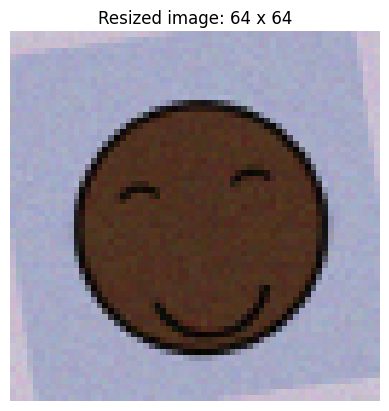

In [ ]:
resized = cv2.resize(image, (64, 64))

print("Original shape:", image.shape)
print("Resized shape:", resized.shape)

plt.imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))
plt.title("Resized image: 64 x 64")
plt.axis("off")
plt.show()

In [ ]:
features = resized.flatten()

print("Number of features:", features.shape[0])

Number of features: 12288


In [ ]:
import numpy as np

features = features.astype(np.float32) / 255.0

print("Minimum pixel value:", features.min())
print("Maximum pixel value:", features.max())

Minimum pixel value: 0.0
Maximum pixel value: 0.8509804


In [ ]:
import os
import cv2
import numpy as np

def load_dataset(dataset_dir):
    X = []
    y = []

    # Dynamically find the class names from the dataset directory
    class_names = sorted([d for d in os.listdir(dataset_dir) if os.path.isdir(os.path.join(dataset_dir, d))])
    print("Detected classes:", class_names)

    # Map class strings to unique integers (e.g., {'anger': 0, 'neutral': 1, 'smile': 2})
    class_to_idx = {name: i for i, name in enumerate(class_names)}

    for class_name in class_names:
        folder = os.path.join(dataset_dir, class_name)
        class_idx = class_to_idx[class_name]

        for filename in os.listdir(folder):
            if not filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp")
            ):
                continue

            image_path = os.path.join(folder, filename)
            image = cv2.imread(image_path)

            if image is None:
                print("Skipping unreadable image:", image_path)
                continue

            image = cv2.resize(image, (64, 64))
            features = image.astype(np.float32).flatten() / 255.0

            X.append(features)
            y.append(class_idx)

    if len(X) == 0:
        raise ValueError(
            "No images were loaded. Check your dataset path."
        )

    return (
        np.array(X, dtype=np.float32),
        np.array(y, dtype=np.int64)
    )

X, y = load_dataset(DATASET_DIR)

print("Feature matrix shape:", X.shape)
print("Label array shape:", y.shape)
print("Classes found:", np.unique(y))

Detected classes: ['anger', 'neutral', 'smile']
Feature matrix shape: (960, 12288)
Label array shape: (960,)
Classes found: [0 1 2]


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 768
Testing samples: 192


In [ ]:
from sklearn.svm import SVC

model = SVC(kernel="linear")
model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


In [ ]:
y_pred = model.predict(X_test)

for actual, predicted in zip(y_test[:10], y_pred[:10]):
    print(f"Actual: {actual}, Predicted: {predicted}")

Actual: 0, Predicted: 1
Actual: 0, Predicted: 0
Actual: 1, Predicted: 1
Actual: 0, Predicted: 0
Actual: 1, Predicted: 1
Actual: 1, Predicted: 1
Actual: 1, Predicted: 1
Actual: 1, Predicted: 1
Actual: 2, Predicted: 2
Actual: 0, Predicted: 1


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {accuracy:.2%}")

Test accuracy: 72.92%


Upload a photo of an emoji/face (anger, neutral, or smile) to test the model:


Saving Screenshot 2026-11-09 130720.png to Screenshot 2026-11-09 130720 (2).png


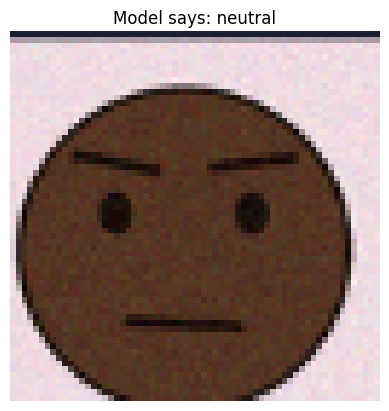

In [ ]:
from google.colab import files
import os
import cv2
import matplotlib.pyplot as plt

# Map indices back to the original emotion names
emotion_classes = ['anger', 'neutral', 'smile']

print("Upload a photo of an emoji/face (anger, neutral, or smile) to test the model:")
uploaded = files.upload()
fname = list(uploaded.keys())[0]

test_img = cv2.imread(fname)
test_img = cv2.resize(test_img, (64, 64))
test_input = test_img.flatten() / 255.0

prediction_idx = model.predict([test_input])[0]
predicted_label = emotion_classes[prediction_idx]

plt.imshow(cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB))
plt.title(f"Model says: {predicted_label}")
plt.axis('off')
plt.show()

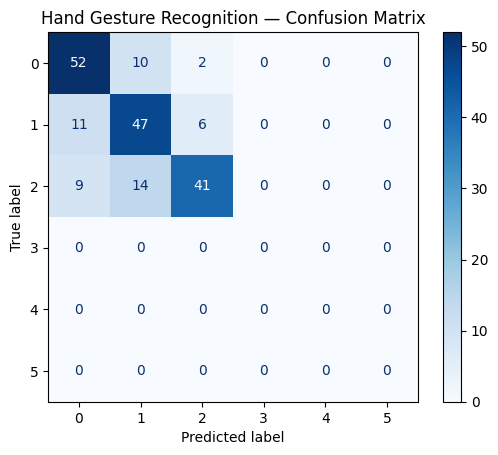

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = [0, 1, 2, 3, 4, 5]

cm = confusion_matrix(y_test, y_pred, labels=labels)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

display.plot(cmap="Blues", values_format="d")
plt.title("Hand Gesture Recognition — Confusion Matrix")
plt.show()

Loading robust training dataset from '/content/emotion_dataset/train'...
Model successfully trained on 300 high-quality augmented images!

Take or upload a photo of an emoji face (anger, neutral, smile):


Saving Screenshot 2026-11-09 130720.png to Screenshot 2026-11-09 130720.png


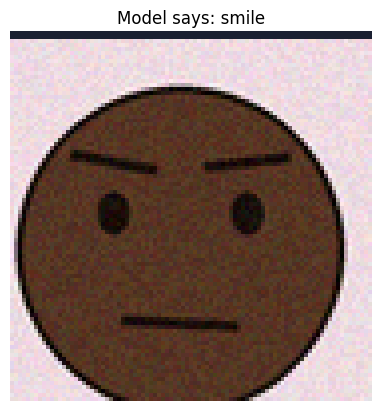

In [ ]:
from google.colab import files
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split

emotion_classes = ['anger', 'neutral', 'smile']

# Ensure we train the SVM model on the robust, generated synthetic dataset
print("Loading robust training dataset from '/content/emotion_dataset/train'...")
dataset_dir = "/content/emotion_dataset/train"

if not os.path.exists(dataset_dir):
    dataset_dir = "emotion_dataset/train"

if not os.path.exists(dataset_dir):
    raise FileNotFoundError("The robust dataset could not be found. Please run cell 0ZdgwWCSN7ZK first to generate the dataset!")

X, y = [], []
for class_idx, class_name in enumerate(emotion_classes):
    folder = os.path.join(dataset_dir, class_name)
    if os.path.exists(folder):
        for filename in os.listdir(folder):
            if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
                img = cv2.imread(os.path.join(folder, filename))
                if img is not None:
                    # Convert BGR to RGB to preserve true colors matching the test input
                    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                    img_resized = cv2.resize(img_rgb, (64, 64))
                    X.append(img_resized.flatten() / 255.0)
                    y.append(class_idx)

if len(X) > 0:
    X_train, X_test, y_train, y_test = train_test_split(np.array(X), np.array(y), test_size=0.2, random_state=42, stratify=y)
    model = SVC(kernel="linear")
    model.fit(X_train, y_train)
    print(f"Model successfully trained on {len(X)} high-quality augmented images!")
else:
    raise ValueError("No images could be loaded from the dataset classes.")

print("\nTake or upload a photo of an emoji face (anger, neutral, smile):")
uploaded = files.upload()
fname = list(uploaded.keys())[0]

test_img = cv2.imread(fname)
test_img_rgb = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)
test_img_resized = cv2.resize(test_img_rgb, (64, 64))
test_input = test_img_resized.flatten() / 255.0

prediction_idx = model.predict([test_input])[0]
predicted_label = emotion_classes[prediction_idx]

plt.imshow(test_img_rgb)
plt.title(f"Model says: {predicted_label}")
plt.axis('off')
plt.show()